In [2]:
import os
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import spacy
import math

nlp = spacy.load("es_core_news_sm", disable=["parser", "ner"])

In [12]:
def eliminar_archivos(ruta, prefijo):
    archivos_eliminados = 0
    
    if not os.path.exists(ruta):
        print(f"La ruta no existe: {ruta}")
        return
        
    with os.scandir(ruta) as entradas:
        for entrada in entradas:
            if entrada.is_file() and entrada.name.startswith(prefijo):
                try:
                    os.remove(entrada.path)
                    archivos_eliminados += 1
                except (FileNotFoundError, PermissionError) as e:
                    print(f"No se pudo eliminar {entrada.name}: {e}")
            
    if archivos_eliminados > 0:
        print(f"Se eliminaron {archivos_eliminados} archivos: {ruta}")
    else:
        print(f"No se encontraron archivos en: {ruta}")

def graf_distro_categoricos(df, cols_cat, sw_exp=False, max_unique_cats=15, max_rows_sample=100000, max_cols=20):
    sns.set_theme(style="whitegrid")
    
    if isinstance(cols_cat, str):
        cols_cat = [cols_cat]
        
    cols_existentes = [col for col in cols_cat if col in df.columns]
    if not cols_existentes:
        print("Ninguna de las columnas categóricas especificadas existe en el DataFrame.")
        return

    if len(cols_existentes) > max_cols:
        print(f"Hay {len(cols_existentes)} columnas categóricas, se graficarán las primeras {max_cols}.")
        cols_existentes = cols_existentes[:max_cols]

    df_plot = df
    if len(df) > max_rows_sample:
        df_plot = df.sample(n=max_rows_sample, random_state=42)

    num_cols_len = len(cols_existentes)
    ncols = 2
    nrows = math.ceil(num_cols_len / ncols)
    
    altura_fig = min(max(6 * nrows, 6), 40)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, altura_fig), squeeze=False)
    axes = axes.flatten()

    for i, col in enumerate(cols_existentes):
        serie = df_plot[col].astype(str).fillna("Nulo / Desconocido")
        counts = serie.value_counts()
        
        if len(counts) > max_unique_cats:
            top_cats = counts.index[:max_unique_cats - 1]
            serie_plot = serie.apply(lambda x: x if x in top_cats else "Otros")
            counts_plot = serie_plot.value_counts()
            titulo_extra = f" (Top {max_unique_cats-1} + Otros)"
        else:
            serie_plot = serie
            counts_plot = counts
            titulo_extra = ""

        df_temp = pd.DataFrame({col: serie_plot})

        ax = sns.countplot(
            data=df_temp, 
            x=col, 
            ax=axes[i], 
            order=counts_plot.index, 
            hue=col, 
            palette="viridis", 
            legend=False
        )
        
        titulo_limpio = f'Distribución de {col.replace("_", " ").capitalize()}{titulo_extra}'
        axes[i].set_title(titulo_limpio, fontsize=13, fontweight='bold', pad=10)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Cantidad de Registros')
        
        rotation = 45 if len(counts_plot) < 10 else 75
        axes[i].tick_params(axis='x', rotation=rotation)

        total_filas = len(serie_plot)

        for p in ax.patches:
            height = p.get_height()
            if height > 0:
                porcentaje = (height / total_filas) * 100
                ax.annotate(
                    f'{porcentaje:.1f}%',
                    (p.get_x() + p.get_width() / 2.0, height),
                    ha='center', 
                    va='bottom',
                    fontsize=9,
                    fontweight='semibold',
                    color='dimgray',
                    xytext=(0, 4), 
                    textcoords='offset points'
                )
        
        y_max = axes[i].get_ylim()[1]
        axes[i].set_ylim(0, y_max * 1.15)

    for j in range(num_cols_len, len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()
    
    plt.close()

def cargar_lexico_nrc(file_nrc):
    word_to_emotions = {}
    word_to_sentiments = {}
    
    emisiones_emociones = {'anger', 'anticipation', 'disgust', 'fear', 'joy', 'sadness', 'surprise', 'trust'}
    emisiones_sentimientos = {'positive', 'negative'}
    
    categories_order = [
        'anger', 'anticipation', 'disgust', 'fear', 'joy', 
        'negative', 'positive', 'sadness', 'surprise', 'trust'
    ]
    
    with open(file_nrc, 'r', encoding='utf-8', errors='ignore') as f:
        for line_num, line in enumerate(f):
            parts = line.strip().split()
            if not parts or (line_num == 0 and 'english' in parts[0].lower()):
                continue
            
            if len(parts) >= 12:
                spanish_word = parts[-1].lower()
                emos = []
                sents = []
                
                for idx, cat in enumerate(categories_order):
                    try:
                        if parts[idx + 1] == '1':
                            if cat in emisiones_emociones:
                                emos.append(cat)
                            elif cat in emisiones_sentimientos:
                                sents.append(cat)
                    except IndexError:
                        continue
                
                if emos:
                    word_to_emotions[spanish_word] = emos
                if sents:
                    word_to_sentiments[spanish_word] = sents
                        
    return word_to_emotions, word_to_sentiments

STOP_WORDS_ES = {
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 
    'de', 'del', 'a', 'en', 'por', 'para', 'con', 'sin', 'su', 'sus', 'es', 'son',
    'que', 'se', 'lo', 'como', 'más', 'fue', 'ha', 'este', 'esta', 'estos', 'estas'
}

def procesar_textos(data_df, word_to_emotions, word_to_sentiments, batch_size=500):
    emotion_maps = []
    sentiment_pols = []
    emotion_mains = []
    sentiment_mains = []
    
    textos = data_df['texto'].fillna('').astype(str).tolist()
    
    for doc in nlp.pipe(textos, batch_size=batch_size):
        conteo_emociones = Counter()
        conteo_sentimientos = Counter()
        
        for token in doc:
            if token.is_alpha and not token.is_stop:
                lema = token.lemma_.lower()
                if lema not in STOP_WORDS_ES:
                    if lema in word_to_emotions:
                        conteo_emociones.update(word_to_emotions[lema])
                    if lema in word_to_sentiments:
                        conteo_sentimientos.update(word_to_sentiments[lema])
        
        main_emo = conteo_emociones.most_common(1)[0][0] if conteo_emociones else None
        
        main_sent = conteo_sentimientos.most_common(1)[0][0] if conteo_sentimientos else None
                        
        emotion_maps.append(dict(conteo_emociones))
        sentiment_pols.append(dict(conteo_sentimientos))
        emotion_mains.append(main_emo)
        sentiment_mains.append(main_sent)
        
    return emotion_maps, sentiment_pols, emotion_mains, sentiment_mains

In [3]:
ruta_data = './data'
ruta_imgs = './static/images'
ruta_nrc = './data/nrc_lexicon'

In [10]:
if __name__ == "__main__":
    data_df = pd.read_csv(os.path.join(ruta_data, 'textos_Bo.csv'), sep=';', encoding='utf-8')
    
    secuencia = data_df.groupby('sigla').cumcount() + 1
    data_df['id'] = data_df['sigla'] + '_' + secuencia.astype(str).str.zfill(4)
    
    file_nrc = os.path.join(ruta_nrc, 'NRC-Emotion-Lexicon-Wordlevel-v0.92_Spanish.txt')

    word_to_emotions, word_to_sentiments = cargar_lexico_nrc(file_nrc)

    emotion_maps, sentiment_pols, emotion_mains, sentiment_mains = procesar_textos(
        data_df, word_to_emotions, word_to_sentiments
    )

    data_df['emotion_map'] = emotion_maps
    data_df['sentiment_pol'] = sentiment_pols
    data_df['emotion_main'] = emotion_mains
    data_df['sentiment_main'] = sentiment_mains
    
    print(data_df.columns)
    
    ruta_salida = os.path.join(ruta_data, 'textos_Bo_procesado.csv')
    data_df.to_csv(ruta_salida, index=False, encoding='utf-8-sig')
    
    print(f"Archivo guardado en: {ruta_salida}")

Index(['titulo', 'texto', 'autor', 'departamento', 'sigla', 'id',
       'emotion_map', 'sentiment_pol', 'emotion_main', 'sentiment_main'],
      dtype='object')
Archivo guardado en: ./data\textos_Bo_procesado.csv


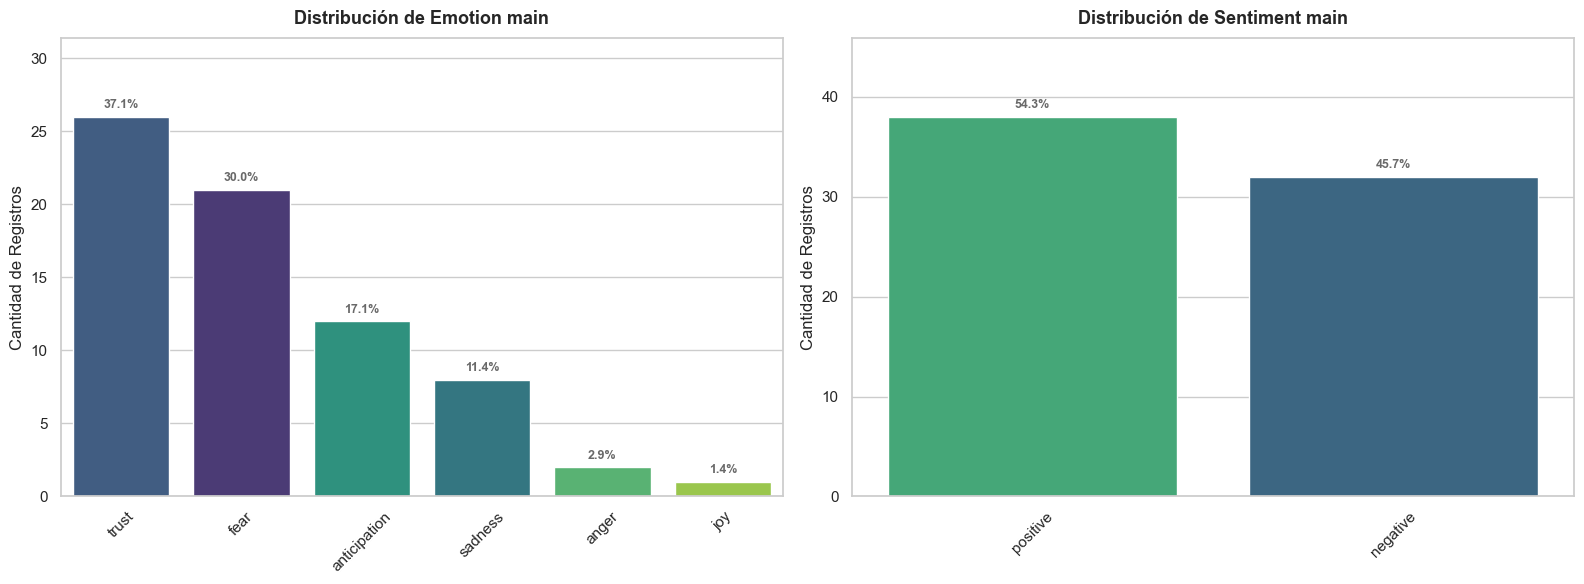

In [11]:
graf_distro_categoricos(data_df, ['emotion_main', 'sentiment_main'])


In [11]:
eliminar_archivos(ruta_imgs, 'p2_')

sns.set_theme(style="whitegrid")

for idx, row in data_df.iterrows():
    record_id = row['id']
    
    emotions = ast.literal_eval(row['emotion_map']) if isinstance(row['emotion_map'], str) else row['emotion_map']
    sentiment = ast.literal_eval(row['sentiment_pol']) if isinstance(row['sentiment_pol'], str) else row['sentiment_pol']
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [3, 1]})
    
    emo_keys = list(emotions.keys())
    emo_values = list(emotions.values())
    
    sns.barplot(x=emo_values, y=emo_keys, ax=ax1, hue=emo_keys, palette="viridis", legend=False, orient='h')
    
    ax1.set_title(f'Distribución Emocional - {record_id}', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Intensidad / Conteo')
    ax1.set_ylabel('')
    
    sent_keys = list(sentiment.keys())
    sent_values = list(sentiment.values())
    colores_polaridad = ['#2ecc71' if k == 'positive' else '#e74c3c' for k in sent_keys]
    
    ax2.bar(sent_keys, sent_values, color=colores_polaridad, edgecolor='black', alpha=0.8)
    ax2.set_title('Polaridad', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Conteo')
    
    plt.tight_layout()
    
    safe_id = str(record_id).replace('/', '_')
    nombre_archivo = os.path.join(ruta_imgs, f"p2_{safe_id}.png")
    
    plt.savefig(nombre_archivo, dpi=300, bbox_inches='tight')
    plt.close()

print(f"Gráficos guardados en '{ruta_imgs}'")

Se eliminaron 70 archivos: static\images
Gráficos guardados en 'static\images'
